## Figure 6: Per-attack-type detection AUC

Three panels (overt, slow, sign-inversion) show the final-score AUC of every method with the 25 honest clients as negatives (per seed, mean over seeds); panel D shows the within-round AUC for the slow attackers over rounds (participants only). Which method is best on which attack type is read off these panels — it is not assumed in advance.


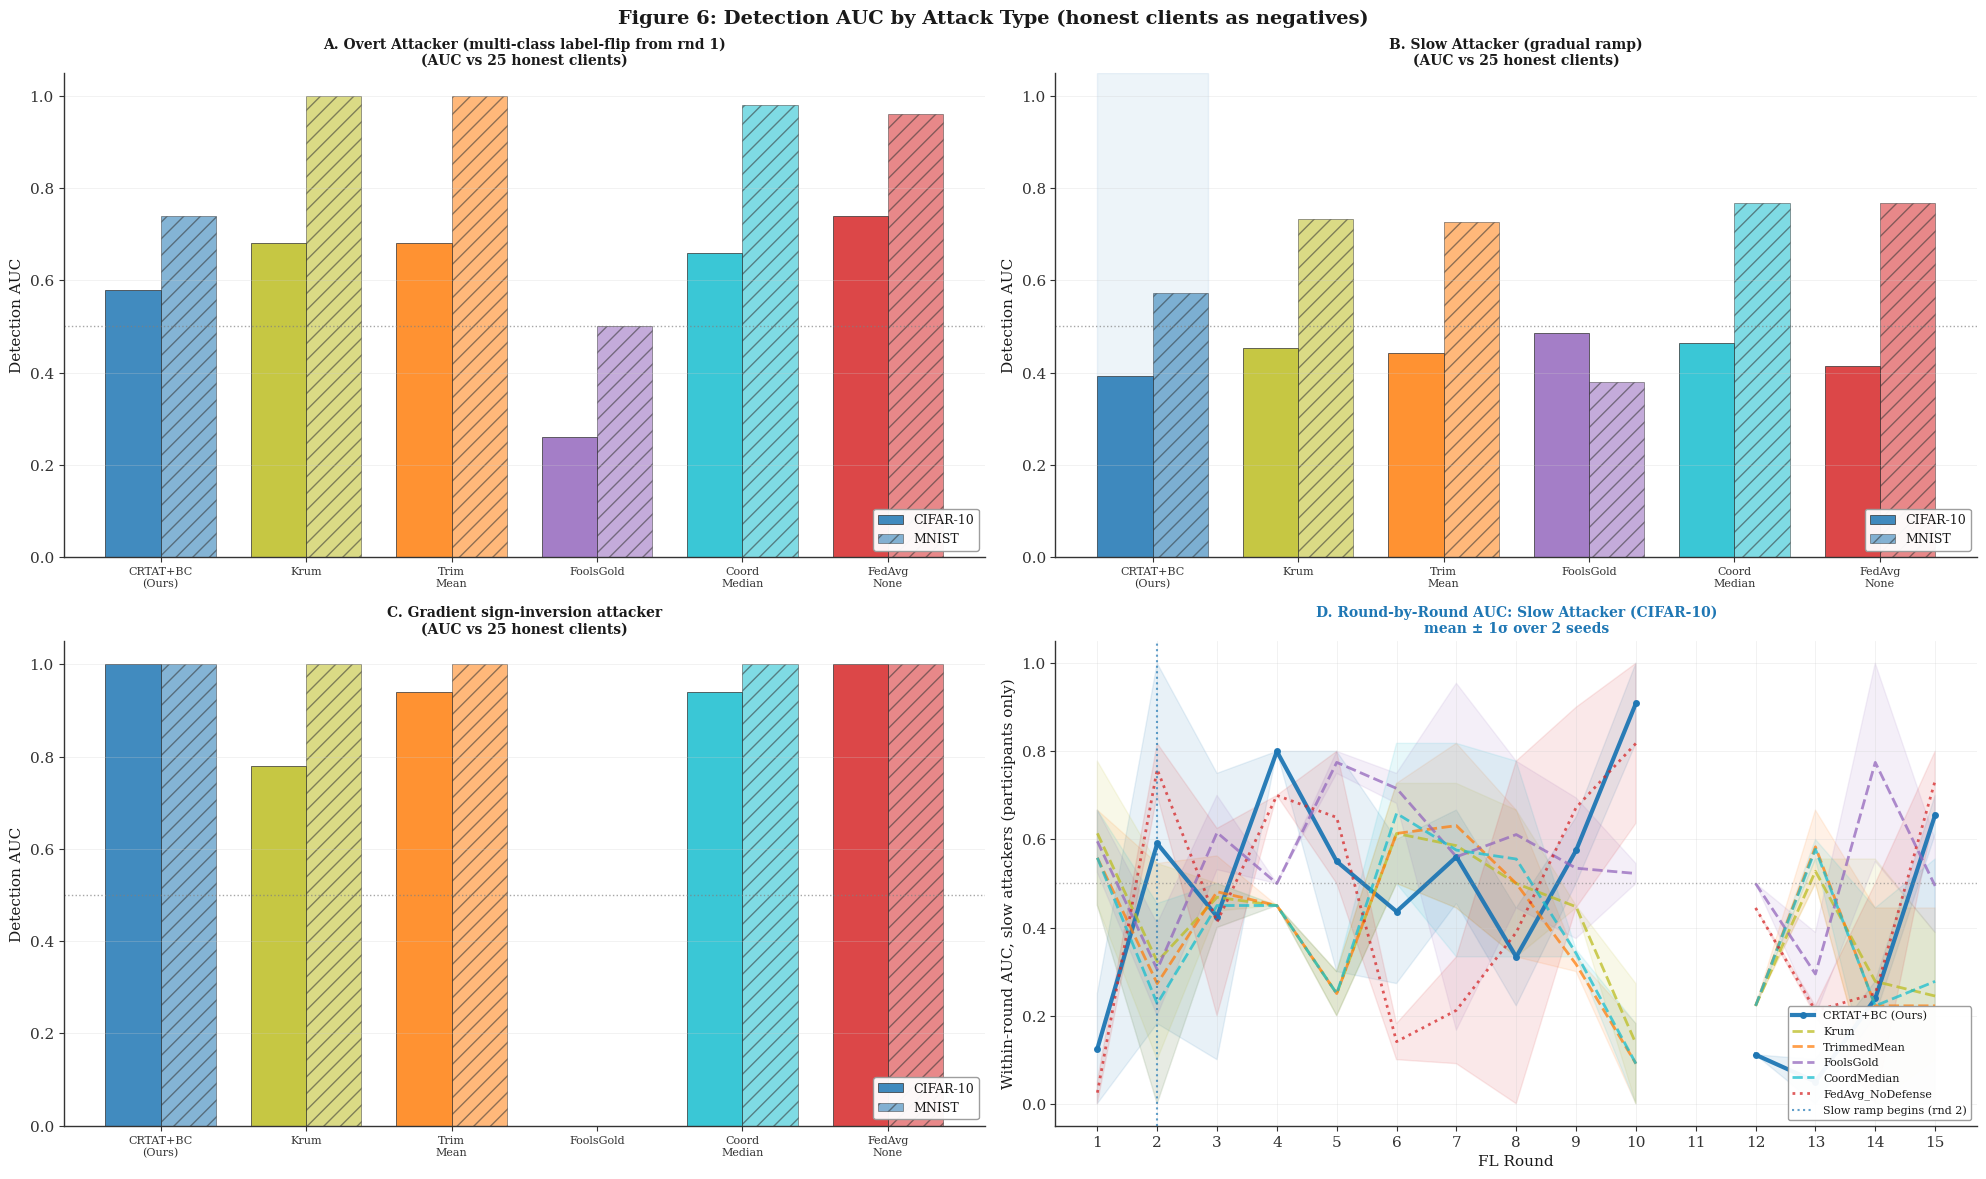

✅ Figure 6 saved (3 attack types · 4 panels).

Table IV — Detection AUC vs 25 honest clients | per-seed AUC → mean±std over seeds [42, 123] | final score = mean of last 3 observed rounds
══════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
Method                         Overt-C         Overt-M          Slow-C          Slow-M           Inv-C           Inv-M        Pooled-C        Pooled-M
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  CRTAT+Blockchain         0.580±0.180     0.740±0.020     0.393±0.047     0.573±0.053     1.000±0.000     1.000±0.000     0.552±0.064     0.692±0.036
  Krum                     0.680±0.280     1.000±0.000     0.453±0.133     0.733±0.107     0.780±0.220     1.000±0.000     0.564±0.068     0.840±0.064
  TrimmedMean              0.680±0.320     1.000±0.000    

In [ ]:
from sklearn.metrics import roc_auc_score

def safe_auc(scores, gt):
    try: return roc_auc_score(gt, scores)
    except: return 0.5

# Table IV protocol: per-seed AUC of final_signal scores, honest clients as negatives, mean ± std over seeds
tbl_c = method_auc_table(results_cifar)
tbl_m = method_auc_table(results_mnist)
_pick = lambda tbl, j: [tbl[m]['mean'][j] for m in METHODS]
auc_overt_c, auc_slow_c, auc_inverse_c, auc_c = (_pick(tbl_c, j) for j in range(4))
auc_overt_m, auc_slow_m, auc_inverse_m, auc_m = (_pick(tbl_m, j) for j in range(4))
final_acc_c = [agg_cifar['acc_mean'][m][-1]*100 for m in METHODS]
final_acc_m = [agg_mnist['acc_mean'][m][-1]*100 for m in METHODS]
final_acc_c_std = [agg_cifar['acc_std'][m][-1]*100 for m in METHODS]
final_acc_m_std = [agg_mnist['acc_std'][m][-1]*100 for m in METHODS]

MDISP = ['CRTAT+BC\n(Ours)','Krum','Trim\nMean',
         'FoolsGold','Coord\nMedian','FedAvg\nNone']
MCOLS = ['#1f77b4','#bcbd22','#ff7f0e','#9467bd','#17becf','#d62728']
xp = np.arange(len(METHODS)); bw = 0.38

fig, axes = plt.subplots(2, 2, figsize=(20, 12))
fig.suptitle('Figure 6: Detection AUC by Attack Type (honest clients as negatives)',
             fontsize=14, fontweight='bold')

# ── Panel A: Overt Attacker ──
ax = axes[0,0]
ax.bar(xp - bw/2, auc_overt_c, bw, color=MCOLS, alpha=0.85,
       edgecolor='#333333', lw=0.6, label='CIFAR-10')
ax.bar(xp + bw/2, auc_overt_m, bw, color=MCOLS, alpha=0.55,
       edgecolor='#333333', lw=0.6, hatch='//', label='MNIST')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.7)
ax.set_xticks(xp); ax.set_xticklabels(MDISP, fontsize=8)
ax.set_ylim([0, 1.05]); ax.set_ylabel('Detection AUC')
ax.set_title('A. Overt Attacker (multi-class label-flip from rnd 1)\n'
             '(AUC vs 25 honest clients)', fontsize=10)
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, axis='y', alpha=0.3)

# ── Panel B: Slow Attacker (CRTAT advantage) ──
ax = axes[0,1]
ax.bar(xp - bw/2, auc_slow_c, bw, color=MCOLS, alpha=0.85,
       edgecolor='#333333', lw=0.6, label='CIFAR-10')
ax.bar(xp + bw/2, auc_slow_m, bw, color=MCOLS, alpha=0.55,
       edgecolor='#333333', lw=0.6, hatch='//', label='MNIST')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.7)
ax.set_xticks(xp); ax.set_xticklabels(MDISP, fontsize=8)
ax.set_ylim([0, 1.05]); ax.set_ylabel('Detection AUC')
ax.set_title('B. Slow Attacker (gradual ramp)\n'
             '(AUC vs 25 honest clients)', fontsize=10)
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, axis='y', alpha=0.3)
ax.axvspan(-bw, bw, alpha=0.08, color='#1f77b4')

# ── Panel C: Gradient Inverter (Krum's territory) ──
ax = axes[1,0]
ax.bar(xp - bw/2, auc_inverse_c, bw, color=MCOLS, alpha=0.85,
       edgecolor='#333333', lw=0.6, label='CIFAR-10')
ax.bar(xp + bw/2, auc_inverse_m, bw, color=MCOLS, alpha=0.55,
       edgecolor='#333333', lw=0.6, hatch='//', label='MNIST')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.7)
ax.set_xticks(xp); ax.set_xticklabels(MDISP, fontsize=8)
ax.set_ylim([0, 1.05]); ax.set_ylabel('Detection AUC')
ax.set_title('C. Gradient sign-inversion attacker\n'
             '(AUC vs 25 honest clients)', fontsize=10)
ax.legend(fontsize=9, loc='lower right'); ax.grid(True, axis='y', alpha=0.3)

# ── Panel D: Round-by-round AUC for slow attacker (early-detection) ──
ax = axes[1,1]
LSTYLE = {'CRTAT+Blockchain':'-', 'Krum':'--', 'TrimmedMean':'--',
          'FoolsGold':'--', 'CoordMedian':'--', 'FedAvg_NoDefense':':'}
LWIDTH = {'CRTAT+Blockchain': 3.0}
n_rounds = agg_cifar['min_rounds']
rounds_axis = list(range(1, n_rounds+1))
for m, col in zip(METHODS, MCOLS):
    mean = agg_cifar['auc_slow_mean'][m]
    std  = agg_cifar['auc_slow_std'][m]
    ax.plot(rounds_axis, mean, color=col, ls=LSTYLE[m], lw=LWIDTH.get(m, 2.0),
            label=m if m != 'CRTAT+Blockchain' else 'CRTAT+BC (Ours)',
            alpha=0.95 if m == 'CRTAT+Blockchain' else 0.75,
            marker='o' if m == 'CRTAT+Blockchain' else None, markersize=4)
    ax.fill_between(rounds_axis, mean-std, mean+std, color=col, alpha=0.10)
ax.axvline(SLOW_RAMP_START, color='#1f77b4', ls=':', lw=1.5, alpha=0.7,
           label=f'Slow ramp begins (rnd {SLOW_RAMP_START})')
ax.axhline(0.5, color='gray', ls=':', lw=1, alpha=0.6)
ax.set_xlabel('FL Round'); ax.set_ylabel('Within-round AUC, slow attackers (participants only)')
ax.set_title('D. Round-by-Round AUC: Slow Attacker (CIFAR-10)\n'
             f'mean ± 1σ over {len(SEEDS)} seeds', fontsize=10, color='#1f77b4')
ax.set_xticks(rounds_axis); ax.set_ylim([-0.05, 1.05])
ax.legend(fontsize=8, loc='lower right'); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig6_detection_3types.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()
print('✅ Figure 6 saved (3 attack types · 4 panels).')

# ── Table IV (numeric) ──
def _pm(tbl, m, j): return f"{tbl[m]['mean'][j]:.3f}±{tbl[m]['std'][j]:.3f}"
print()
print(f'Table IV — Detection AUC vs 25 honest clients | per-seed AUC → mean±std over seeds {SEEDS} | '
      f'final score = mean of last {FINAL_K} observed rounds')
print('═' * 150)
print(f'{"Method":<22}' + ''.join(f'{h:>16}' for h in ['Overt-C','Overt-M','Slow-C','Slow-M','Inv-C','Inv-M','Pooled-C','Pooled-M']))
print('─' * 150)
_cols = [(0,tbl_c),(0,tbl_m),(1,tbl_c),(1,tbl_m),(2,tbl_c),(2,tbl_m),(3,tbl_c),(3,tbl_m)]
for m in AUC_METHODS:
    print(f'  {m:<20}' + ''.join(f'{_pm(t, m, j):>16}' for (j, t) in _cols))
print('═' * 150)
print('  AUC < 0.5 means the attacker is ranked as LESS suspicious than honest clients on average — report it as such.')
print('  TemporalConsistency = simplified FLDetector-inspired baseline (not FLDetector).')
print_baseline_definitions()